# Exploratory Data Analysis of GDSC2 Drug Sensitivity Data

## 1. Project Overview

### Objective
The goal of this project is to perform a comprehensive Exploratory Data Analysis (EDA) of the GDSC2 drug sensitivity dataset.

The analysis focuses on assessing data quality, understanding drug response distributions, exploring relationships between variables, and identifying potential biological patterns.

### Main Goals
- Assess the quality and reliability of the dataset.
- Explore drug response measurements.
- Compare drug responses across drugs and cancer types.
- Investigate relationships between drug response variables.

## 2. Dataset Description

The dataset used in this project is the GDSC2 fitted dose-response dataset.

- **File name:** `GDSC2_fitted_dose_response_27Oct23.xlsx`
- **Initial number of rows:** 242,036
- **Number of columns:** 16
- **Main focus:** Drug sensitivity measurements across cancer cell models.

### Key Variables
- `CELL_LINE_NAME`: Name of the cell line.
- `SANGER_MODEL_ID`: Identifier of the cell model.
- `CANCER_TYPE`: Cancer type associated with the model.
- `DRUG_NAME`: Name of the drug.
- `DRUG_ID`: Identifier of the drug.
- `LN_IC50`: Natural logarithm of the estimated IC50.
- `AUC`: Area under the dose-response curve.
- `RMSE`: Error measure for the fitted dose-response curve.
- `Z_SCORE`: Standardized drug response measure.

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
gdsc = pd.read_excel("GDSC2_fitted_dose_response_27Oct23.xlsx")

## 3. Initial Data Inspection

The first step is to inspect the dataset's dimensions, structure, column names, and data types.

This helps establish the basic structure of the data before performing data quality checks.

In [5]:
gdsc.shape

(242036, 16)

In [6]:
gdsc.info()

<class 'pandas.DataFrame'>
RangeIndex: 242036 entries, 0 to 242035
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   DATASET          242036 non-null  str    
 1   NLME_RESULT_ID   242036 non-null  int64  
 2   NLME_CURVE_ID    242036 non-null  int64  
 3   CELL_LINE_NAME   242036 non-null  str    
 4   SANGER_MODEL_ID  242036 non-null  str    
 5   CANCER_TYPE      242036 non-null  str    
 6   DRUG_ID          242036 non-null  int64  
 7   DRUG_NAME        242036 non-null  str    
 8   PUTATIVE_TARGET  214881 non-null  str    
 9   PATHWAY_NAME     242036 non-null  str    
 10  MIN_CONC         242036 non-null  float64
 11  MAX_CONC         242036 non-null  float64
 12  LN_IC50          242036 non-null  float64
 13  AUC              242036 non-null  float64
 14  RMSE             242036 non-null  float64
 15  Z_SCORE          242036 non-null  float64
dtypes: float64(6), int64(3), str(7)
memory usage: 29.

In [7]:
gdsc.head()

,DATASET,NLME_RESULT_ID,NLME_CURVE_ID,CELL_LINE_NAME,SANGER_MODEL_ID,CANCER_TYPE,DRUG_ID,DRUG_NAME,PUTATIVE_TARGET,PATHWAY_NAME,MIN_CONC,MAX_CONC,LN_IC50,AUC,RMSE,Z_SCORE
0,GDSC2,343,15946310,PFSK-1,SIDM01132,Other Solid Cancers,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-1.463887,0.930220,0.089052,0.433123
1,GDSC2,343,15946548,A673,SIDM00848,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-4.869455,0.614970,0.111351,-1.421100
2,GDSC2,343,15946830,ES5,SIDM00263,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-3.360586,0.791072,0.142855,-0.599569
3,GDSC2,343,15947087,ES7,SIDM00269,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-5.044940,0.592660,0.135539,-1.516647
4,GDSC2,343,15947369,EW-11,SIDM00203,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-3.741991,0.734047,0.128059,-0.807232


In [8]:
gdsc.describe()

,NLME_RESULT_ID,NLME_CURVE_ID,DRUG_ID,MIN_CONC,MAX_CONC,LN_IC50,AUC,RMSE,Z_SCORE
count,242036.0,2.420360e+05,242036.000000,242036.000000,242036.000000,242036.000000,242036.000000,242036.000000,2.420360e+05
mean,343.0,1.606806e+07,1594.042444,0.023143,23.462279,2.817079,0.882592,0.082779,7.312962e-10
std,0.0,7.028749e+04,398.740714,0.158738,158.622810,2.762229,0.146998,0.042695,9.993925e-01
min,343.0,1.594631e+07,1003.000000,0.000010,0.010000,-8.747724,0.006282,0.003274,-8.254501e+00
25%,343.0,1.600719e+07,1149.000000,0.003002,3.000000,1.508018,0.849449,0.051107,-6.568485e-01
50%,343.0,1.606807e+07,1631.000000,0.010005,10.000000,3.236731,0.944196,0.076083,1.058000e-02
75%,343.0,1.612893e+07,1912.000000,0.010005,10.000000,4.700110,0.974934,0.106105,6.560362e-01
max,343.0,1.618978e+07,2499.000000,2.001054,2000.000000,13.820189,0.998904,0.299984,7.978776e+00


## 4. Phase A — Data Quality Assessment

Before analyzing drug response patterns, the dataset must be checked for missing values, duplicate records, identifier inconsistencies, and unusual numerical values.

The purpose of this stage is to understand potential data quality issues before deciding whether any cleaning is necessary.

### 4.1 Missing Values

Missing values in drug target annotations are particularly relevant because they may limit target-level biological interpretation.

In [9]:
gdsc.info()

<class 'pandas.DataFrame'>
RangeIndex: 242036 entries, 0 to 242035
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   DATASET          242036 non-null  str    
 1   NLME_RESULT_ID   242036 non-null  int64  
 2   NLME_CURVE_ID    242036 non-null  int64  
 3   CELL_LINE_NAME   242036 non-null  str    
 4   SANGER_MODEL_ID  242036 non-null  str    
 5   CANCER_TYPE      242036 non-null  str    
 6   DRUG_ID          242036 non-null  int64  
 7   DRUG_NAME        242036 non-null  str    
 8   PUTATIVE_TARGET  214881 non-null  str    
 9   PATHWAY_NAME     242036 non-null  str    
 10  MIN_CONC         242036 non-null  float64
 11  MAX_CONC         242036 non-null  float64
 12  LN_IC50          242036 non-null  float64
 13  AUC              242036 non-null  float64
 14  RMSE             242036 non-null  float64
 15  Z_SCORE          242036 non-null  float64
dtypes: float64(6), int64(3), str(7)
memory usage: 29.

In [10]:
gdsc['PUTATIVE_TARGET'].isna().sum() / len(gdsc) * 100

np.float64(11.219405377712405)

**Interpretation:** Only `PUTATIVE_TARGET` contains missing values, with 27,155 missing entries (11.22%).

### 4.2 Duplicate Records

Exact duplicate rows are checked to determine whether identical records occur in the dataset.

In [11]:
gdsc.duplicated().sum()

np.int64(0)

### 4.3 Identifier Consistency

Cell line names and Sanger model identifiers are examined to check whether the identifiers map consistently to one another. Drug names and drug IDs are also checked because a single drug name may be associated with multiple IDs.

In [12]:
gdsc['CELL_LINE_NAME'].value_counts()

CELL_LINE_NAME
PC-14        295
HT-29        295
SW620        295
A375         294
C32          294
            ... 
SNU-1040     148
LNZTA3WT4     99
COR-L95       99
HCC202        14
RH-18         12
Name: count, Length: 969, dtype: int64

In [13]:
gdsc['SANGER_MODEL_ID'].value_counts()

SANGER_MODEL_ID
SIDM00237    295
SIDM00136    295
SIDM00841    295
SIDM00795    294
SIDM00890    294
            ... 
SIDM00217    148
SIDM01220     99
SIDM00521     99
SIDM00870     14
SIDM00454     12
Name: count, Length: 969, dtype: int64

In [14]:
gdsc.groupby("CELL_LINE_NAME")["SANGER_MODEL_ID"].nunique().max()

np.int64(1)

In [15]:
gdsc.groupby("SANGER_MODEL_ID")["CELL_LINE_NAME"].nunique().max()

np.int64(1)

In [16]:
gdsc.groupby("DRUG_NAME")["DRUG_ID"].nunique().loc[lambda x: x > 1]

DRUG_NAME
Acetalax        2
Dactinomycin    2
Docetaxel       2
Fulvestrant     2
GSK343          2
Oxaliplatin     2
Selumetinib     2
Ulixertinib     2
Uprosertib      2
Name: DRUG_ID, dtype: int64

**Interpretation:**
- Each `CELL_LINE_NAME` maps to only one `SANGER_MODEL_ID`.
- Each `SANGER_MODEL_ID` maps to only one `CELL_LINE_NAME`.
- Nine drug names are associated with multiple `DRUG_ID` values;

In [17]:
gdsc[gdsc["DRUG_NAME"].isin(
    [
    "Acetalax", "Dactinomycin", "Docetaxel",
    "Fulvestrant", "GSK343", "Oxaliplatin",
    "Selumetinib", "Ulixertinib", "Uprosertib"
])][["DRUG_NAME", "DRUG_ID", "PUTATIVE_TARGET", "PATHWAY_NAME"]].drop_duplicates().sort_values("DRUG_NAME")

,DRUG_NAME,DRUG_ID,PUTATIVE_TARGET,PATHWAY_NAME
145052,Acetalax,1804,NaN,Unclassified
144335,Acetalax,1803,NaN,Unclassified
180104,Dactinomycin,1911,RNA polymerase,Other
148637,Dactinomycin,1811,RNA polymerase,Other
153655,Docetaxel,1819,Microtubule stabiliser,Mitosis
3212,Docetaxel,1007,Microtubule stabiliser,Mitosis
69109,Fulvestrant,1200,ESR,Hormone-related
152221,Fulvestrant,1816,ESR,Hormone-related
207847,GSK343,2037,EZH2,Chromatin histone methylation
117542,GSK343,1627,EZH2,Chromatin histone methylation


### 4.4 Numerical Data Validation

Numerical variables are checked for missing, non-finite, and potentially invalid values. This step helps identify data quality issues before analyzing drug response distributions.

In [18]:
float_vaiables = gdsc.select_dtypes(include="float")

In [19]:
float_vaiables.min()

MIN_CONC    0.000010
MAX_CONC    0.010000
LN_IC50    -8.747724
AUC         0.006282
RMSE        0.003274
Z_SCORE    -8.254501
dtype: float64

In [20]:
float_vaiables.max()

MIN_CONC       2.001054
MAX_CONC    2000.000000
LN_IC50       13.820189
AUC            0.998904
RMSE           0.299984
Z_SCORE        7.978776
dtype: float64

In [21]:
gdsc[gdsc["MIN_CONC"] > gdsc["MAX_CONC"]][["DRUG_NAME", "MIN_CONC", "MAX_CONC"]].head()

,DRUG_NAME,MIN_CONC,MAX_CONC


## 5. Cell Line and Cancer Type Analysis

This section explores the cancer cell lines included in the GDSC2 dataset and examines how these models are distributed across cancer types.

The analysis helps identify the diversity of cancer types represented in the dataset and whether some cancer types have greater cell line coverage than others.

### 5.1 Cell Line Identifiers

The dataset contains cell line names and Sanger model identifiers. 
The following analysis examines the number of unique cell line models and the number of drug response records associated with each model.

In [22]:
gdsc["SANGER_MODEL_ID"].nunique()

969

In [23]:
gdsc["SANGER_MODEL_ID"].value_counts()

SANGER_MODEL_ID
SIDM00237    295
SIDM00136    295
SIDM00841    295
SIDM00795    294
SIDM00890    294
            ... 
SIDM00217    148
SIDM01220     99
SIDM00521     99
SIDM00870     14
SIDM00454     12
Name: count, Length: 969, dtype: int64

### 5.2 Distribution Across Cancer Types

The number of unique cancer types and the number of cell line models represented in each cancer type are examined to understand the composition of the dataset.

In [24]:
gdsc["CANCER_TYPE"].nunique()

42

In [25]:
(gdsc.groupby("CANCER_TYPE")["SANGER_MODEL_ID"].nunique().sort_values(ascending=False))

CANCER_TYPE
Non-Small Cell Lung Carcinoma         88
Small Cell Lung Carcinoma             58
Melanoma                              54
Breast Carcinoma                      52
Colorectal Carcinoma                  48
Ovarian Carcinoma                     40
Glioblastoma                          37
B-Cell Non-Hodgkin's Lymphoma         37
Kidney Carcinoma                      32
Neuroblastoma                         31
Other Solid Cancers                   31
Pancreatic Carcinoma                  30
Acute Myeloid Leukemia                29
Gastric Carcinoma                     28
Esophageal Squamous Cell Carcinoma    26
Oral Cavity Carcinoma                 23
Ewing's Sarcoma                       23
Mesothelioma                          21
B-Lymphoblastic Leukemia              20
Bladder Carcinoma                     18
T-Lymphoblastic Leukemia              18
Head and Neck Carcinoma               18
Thyroid Gland Carcinoma               16
Other Sarcomas                        15
Squa

**Interpretation**

The GDSC2 dataset contains 969 unique cell line models across 42 cancer types. Cell line coverage varies substantially across cancer types.

- Non-Small Cell Lung Carcinoma : highest number of unique models (88 models). 
- Biliary Tract Carcinoma : lowest coverage (4 models).

### These differences should be considered when comparing drug responses across cancer types.

## 6. Drug Analysis and Coverage

In this section, we examine the drugs included in the GDSC2 dataset, their distribution, and the number of unique cell line models tested for each drug. This helps us understand how much data is available for comparing drug responses.

In [26]:
gdsc["DRUG_NAME"].nunique()

286

In [27]:
gdsc["DRUG_ID"].nunique()

295

In [28]:
gdsc.groupby("DRUG_ID")["DRUG_NAME"].nunique().max()

np.int64(1)

In [29]:
gdsc.groupby("DRUG_NAME")["DRUG_ID"].nunique().max()

np.int64(2)

In [30]:
multiples = gdsc.groupby("DRUG_NAME")["DRUG_ID"].nunique().loc[lambda x: x > 1]
multiples

DRUG_NAME
Acetalax        2
Dactinomycin    2
Docetaxel       2
Fulvestrant     2
GSK343          2
Oxaliplatin     2
Selumetinib     2
Ulixertinib     2
Uprosertib      2
Name: DRUG_ID, dtype: int64

In [31]:
gdsc[gdsc["DRUG_NAME"].isin(multiples.index)][["DRUG_NAME", "DRUG_ID", "PUTATIVE_TARGET", "PATHWAY_NAME"]].drop_duplicates().sort_values("DRUG_NAME")

,DRUG_NAME,DRUG_ID,PUTATIVE_TARGET,PATHWAY_NAME
145052,Acetalax,1804,NaN,Unclassified
144335,Acetalax,1803,NaN,Unclassified
180104,Dactinomycin,1911,RNA polymerase,Other
148637,Dactinomycin,1811,RNA polymerase,Other
153655,Docetaxel,1819,Microtubule stabiliser,Mitosis
3212,Docetaxel,1007,Microtubule stabiliser,Mitosis
69109,Fulvestrant,1200,ESR,Hormone-related
152221,Fulvestrant,1816,ESR,Hormone-related
207847,GSK343,2037,EZH2,Chromatin histone methylation
117542,GSK343,1627,EZH2,Chromatin histone methylation


**Drug Identifier Consistency**

The analysis identified 9 drug names associated with two different `DRUG_ID` values in the GDSC2 dataset. 
This indicates that drug names and drug identifiers do not have a strictly one-to-one relationship in all records.

#### Drug Coverage

In [32]:
gdsc.groupby("DRUG_NAME")["SANGER_MODEL_ID"].nunique()

DRUG_NAME
123138                   717
123829                   717
150412                   717
5-Fluorouracil           968
5-azacytidine            740
                        ... 
ZM447439                 944
Zoledronate              717
alpha-lipoic acid        735
ascorbate (vitamin C)    732
glutathione              732
Name: SANGER_MODEL_ID, Length: 286, dtype: int64

In [33]:
drug_coverage = gdsc.groupby("DRUG_NAME")["SANGER_MODEL_ID"].nunique()
drug_coverage.describe()

count    286.000000
mean     824.293706
std      175.267528
min      225.000000
25%      717.000000
50%      894.000000
75%      957.750000
max      969.000000
Name: SANGER_MODEL_ID, dtype: float64

In [34]:
drug_coverage.sort_values().head(10)

DRUG_NAME
Tretinoin         225
CHIR-99021        225
BX795             225
SL0101            225
CCT-018159        225
Bicalutamide      225
Elesclomol        225
Piperlongumine    225
IOX2              225
SB505124          265
Name: SANGER_MODEL_ID, dtype: int64

In [35]:
drug_coverage.sort_values().tail(10)

DRUG_NAME
Pictilisib        967
PD0325901         968
Camptothecin      968
Nutlin-3a (-)     968
Palbociclib       968
MK-2206           968
Docetaxel         968
5-Fluorouracil    968
Staurosporine     968
MG-132            969
Name: SANGER_MODEL_ID, dtype: int64

**Drug Coverage Summary**

The GDSC2 dataset contains 286 unique drug names. The number of unique cell line models tested per drug ranges from 225 to 969, with a mean of approximately 824 and a median of 894 models.

The median is higher than the mean, indicating that at least some drugs have substantially lower coverage than many others. The middle 50% of drugs were tested on 717 to approximately 958 cell line models. Overall, most drugs have relatively broad coverage, although the number of available models varies across drugs.

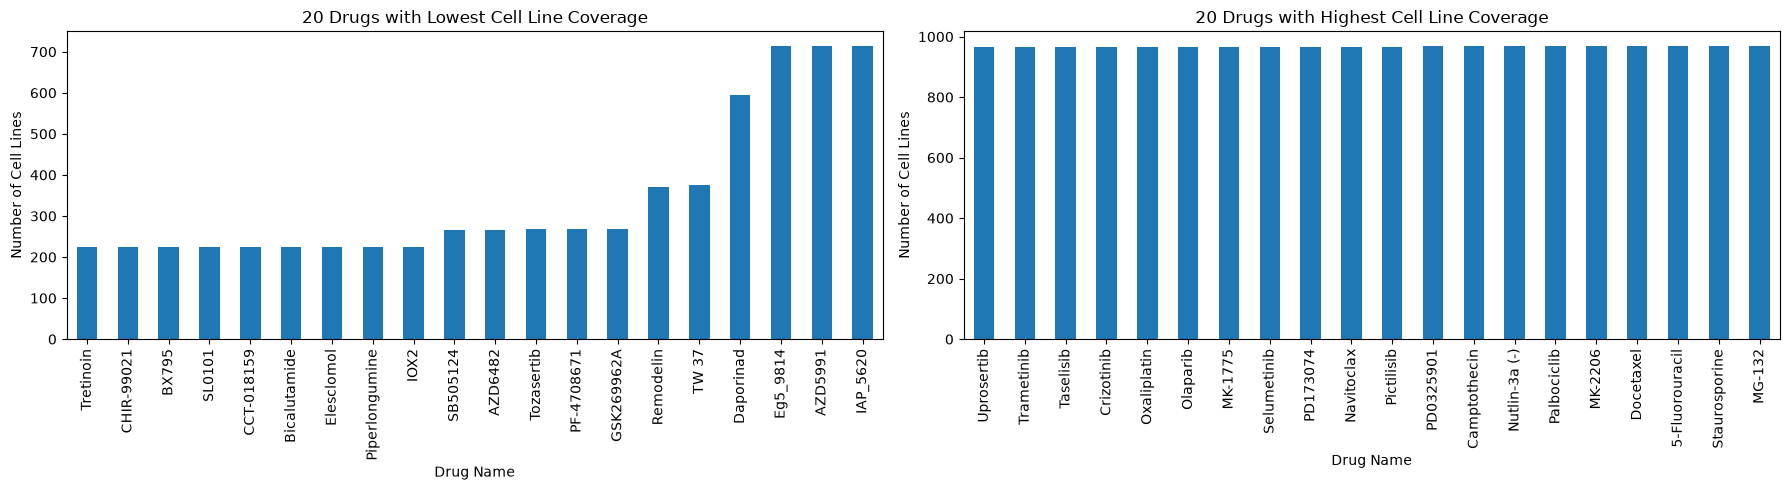

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# 20 drugs with lowest coverage
drug_coverage.sort_values().head(20).plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_xlabel("Drug Name")
axes[0].set_ylabel("Number of Cell Lines")
axes[0].set_title("20 Drugs with Lowest Cell Line Coverage")
axes[0].tick_params(axis="x", rotation=90)

# 20 drugs with highest coverage
drug_coverage.sort_values().tail(20).plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_xlabel("Drug Name")
axes[1].set_ylabel("Number of Cell Lines")
axes[1].set_title("20 Drugs with Highest Cell Line Coverage")
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

## 7. Drug Targets, Pathways, and Concentrations

This section explores the putative targets and biological pathways associated with the drugs in the GDSC2 dataset. It also examines the concentration ranges used in drug sensitivity experiments.

In [37]:
gdsc['PUTATIVE_TARGET'].unique()

<StringArray>
[                                'TOP1',
             'Microtubule destabiliser',
                      'DNA crosslinker',
                       'Antimetabolite',
               'Microtubule stabiliser',
                        'Retinoic acid',
                                 'EGFR',
                  'BCL2, BCL-XL, BCL-W',
 'HDAC inhibitor Class I, IIa, IIb, IV',
                                  'ABL',
 ...
                                'EP300',
                                'SETD8',
                             'PI3Kbeta',
                                 'AKT1',
               'BRD2, BRD3, BRD4, BRDT',
                                'EGLN1',
                                 'WIP1',
                           'Mutant RAS',
                'anti-oxidant proteins',
                           'Metabolism']
Length: 186, dtype: str

In [38]:
gdsc['PUTATIVE_TARGET'].isnull().sum()

np.int64(27155)

In [39]:
gdsc['PUTATIVE_TARGET'].value_counts()

PUTATIVE_TARGET
PARP1, PARP2                             4714
MEK1, MEK2                               4547
TOP1                                     4325
EGFR                                     3836
TNKS1, TNKS2                             3699
                                         ... 
TBK1, PDK1 (PDPK1), IKK, AURKB, AURKC     225
RSK, AURKB, PIM1, PIM3                    225
Induces reactive oxygen species           225
AR                                        225
EGLN1                                     225
Name: count, Length: 185, dtype: int64

**Putative Target Analysis**

The GDSC2 dataset contains 185 unique putative target annotations. However, 27,155 records (approximately 11.22%) have missing target information.

Among the available annotations, `PARP1, PARP2` has the highest frequency (4,714 records).

In [40]:
gdsc["PATHWAY_NAME"].unique()

<StringArray>
[                  'DNA replication',                           'Mitosis',
                             'Other',                    'EGFR signaling',
              'Apoptosis regulation',     'Chromatin histone acetylation',
                     'ABL signaling',                'ERK MAPK signaling',
               'PI3K/MTOR signaling',                  'Genome integrity',
                    'Other, kinases', 'Protein stability and degradation',
                     'RTK signaling',                        'Cell cycle',
                     'WNT signaling',             'JNK and p38 signaling',
                       'p53 pathway',                      'Cytoskeleton',
                   'IGF1R signaling',                   'Hormone-related',
     'Chromatin histone methylation',                        'Metabolism',
                   'Chromatin other',                      'Unclassified']
Length: 24, dtype: str

In [41]:
gdsc["PATHWAY_NAME"].value_counts()

PATHWAY_NAME
Unclassified                         24979
PI3K/MTOR signaling                  22724
Other                                21402
DNA replication                      17650
Other, kinases                       17277
ERK MAPK signaling                   13350
Genome integrity                     12221
Cell cycle                           11620
Apoptosis regulation                 10828
Chromatin histone methylation        10612
RTK signaling                        10573
Chromatin other                       8576
Chromatin histone acetylation         8162
WNT signaling                         7631
Protein stability and degradation     7087
EGFR signaling                        6734
Mitosis                               6453
IGF1R signaling                       5512
Metabolism                            4802
Hormone-related                       3820
p53 pathway                           3776
Cytoskeleton                          3387
JNK and p38 signaling                 190

**Pathway Analysis**

The GDSC2 dataset contains 24 unique pathway categories, with no missing values in `PATHWAY_NAME`.

`Unclassified` is the most frequent category, accounting for 24,979 experimental records, followed by `PI3K/MTOR signaling` (22,724).

The high frequency of `Unclassified` is an important observation because it indicates that this is the most commonly assigned category in the dataset. This may limit the interpretation of pathway-specific drug response patterns, as these records are not assigned to a more specific pathway category.

In [42]:
gdsc[["MIN_CONC", "MAX_CONC"]].describe()

,MIN_CONC,MAX_CONC
count,242036.000000,242036.000000
mean,0.023143,23.462279
std,0.158738,158.622810
min,0.000010,0.010000
25%,0.003002,3.000000
50%,0.010005,10.000000
75%,0.010005,10.000000
max,2.001054,2000.000000


**Drug Concentration Analysis**

The `MIN_CONC` and `MAX_CONC` columns contain 242,036 non-missing values each. The minimum concentration ranges from 0.00001 to approximately 2.001, while the maximum concentration ranges from 0.01 to 2,000.

The median minimum concentration is approximately 0.010005, and the median maximum concentration is 10. The third quartile equals the median for both columns, indicating that at least 75% of the observations have concentration values at or below these respective levels.

The concentration ranges vary considerably across records. These values describe the experimental concentration ranges recorded in the dataset; their biological or experimental interpretation depends on the units and assay protocol. No rows were found where `MIN_CONC` exceeded `MAX_CONC`.

## 8. Drug Response

In this section, we explore the distributions of the main drug response variables: `LN_IC50`, `AUC`, `RMSE`, and `Z_SCORE`. The goal is to understand their ranges, distributions, and potential unusual values before investigating relationships between drug response and other variables.

In [44]:
columns = ["LN_IC50", "AUC", "RMSE", "Z_SCORE"]

gdsc[columns].describe().round(2)

,LN_IC50,AUC,RMSE,Z_SCORE
count,242036.00,242036.00,242036.00,242036.00
mean,2.82,0.88,0.08,0.00
std,2.76,0.15,0.04,1.00
min,-8.75,0.01,0.00,-8.25
25%,1.51,0.85,0.05,-0.66
50%,3.24,0.94,0.08,0.01
75%,4.70,0.97,0.11,0.66
max,13.82,1.00,0.30,7.98


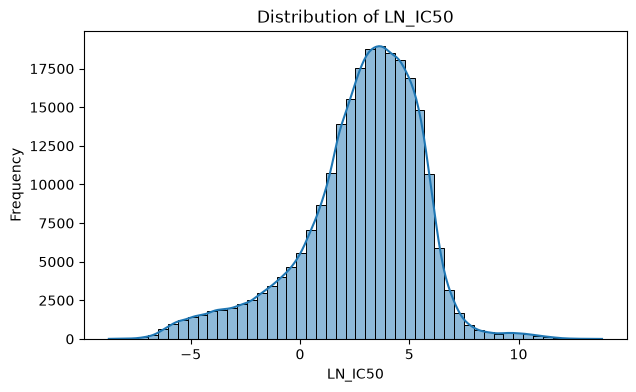

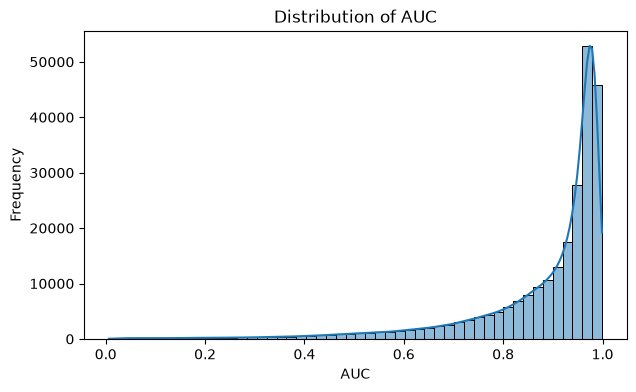

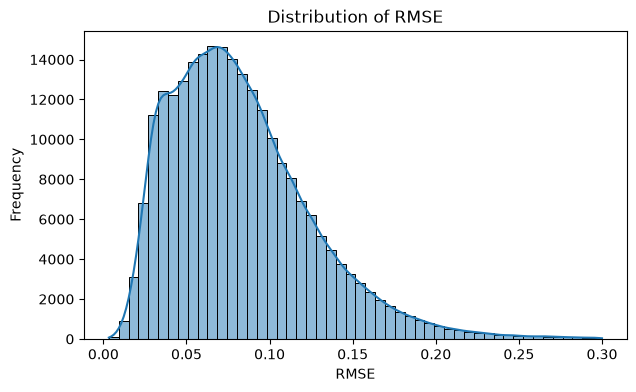

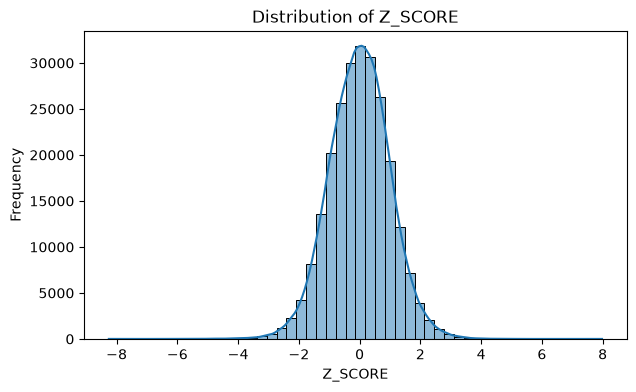

In [45]:
for col in columns:
    plt.figure(figsize=(7, 4))
    
    sns.histplot(data=gdsc, x=col, bins=50, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    
    plt.show()

### Interpretation of LN_IC50 Distribution

The distribution of `LN_IC50` is unimodal, with most observations concentrated between approximately 2 and 6 and a peak around 3.5–4. The distribution is asymmetric, with a longer tail toward lower values and a smaller tail extending toward higher values. A limited number of observations occur at the extremes of the distribution. These values may require further investigation, but they cannot be classified as errors based on the histogram alone. Overall, the plot illustrates the variability in drug response measurements across the dataset.

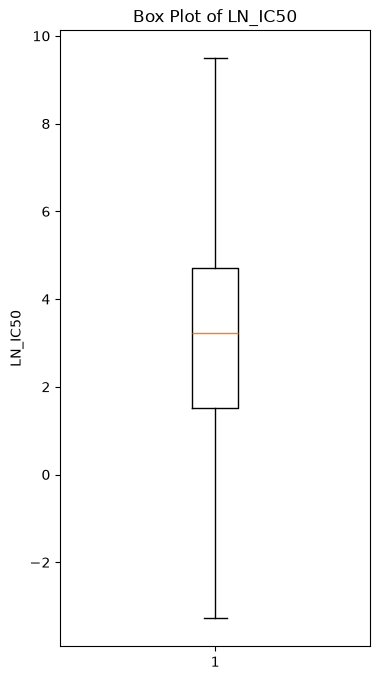

In [57]:
plt.figure(figsize=(4, 8))

plt.boxplot(gdsc["LN_IC50"], showfliers=False)

plt.title("Box Plot of LN_IC50")
plt.ylabel("LN_IC50")

plt.show()

Text(0, 0.5, 'LN_IC50')

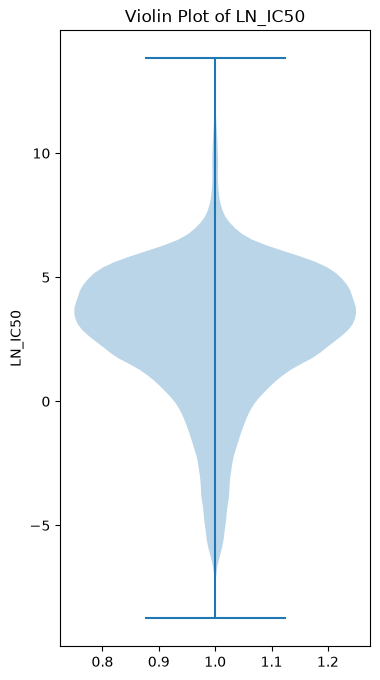

In [55]:
plt.figure(figsize=(4, 8))

plt.violinplot(gdsc["LN_IC50"])

plt.title("Violin Plot of LN_IC50")
plt.ylabel("LN_IC50")


In [46]:
Q1 = gdsc["LN_IC50"].quantile(0.25)
Q3 = gdsc["LN_IC50"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [65]:
outliers = gdsc[(gdsc["LN_IC50"] < lower_bound) | (gdsc["LN_IC50"] > upper_bound)]
len(outliers)

11543

In [66]:
len(outliers)/ len(gdsc) * 100

4.769125254094432

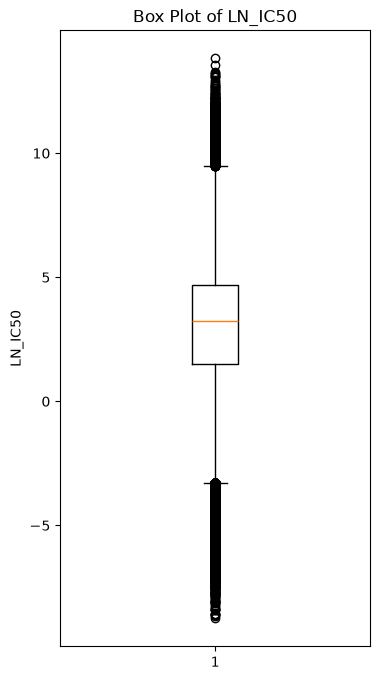

In [58]:
plt.figure(figsize=(4, 8))

plt.boxplot(gdsc["LN_IC50"])

plt.title("Box Plot of LN_IC50")
plt.ylabel("LN_IC50")

plt.show()

### Outlier Detection in LN_IC50

Potential outliers in `LN_IC50` were identified using the Interquartile Range (IQR) method. 
The first quartile (Q1) was 1.508 and the third quartile (Q3) was 4.700, resulting in an IQR of 3.192. 
The lower and upper bounds were calculated as -3.280 and 9.488, respectively.

A total of 11,543 records (4.77% of the dataset) fell outside these bounds.